# Lab 3: Sampling, train/test split and Random Forest land-cover classification (Python)

Python port of Lab 3 (Class 6). Each ArcGIS step is quoted word for word from the lab handout (the quote blocks),
followed by a short **In Python** note on how it is done here.

**Data.** `LAB3_DATA` is the folder with `reference_sample.shp` and the two composites (default `data/Lab_3`). To
classify your own Lab 2 composites instead of the ones shipped with Lab 3, set `LAB3_COMPOSITES=outputs/Lab_2`.
Outputs go to `outputs/Lab_3` (override with `LAB3_OUT`).

**Where Python differs from the ArcGIS steps**
- No intermediate rasters, point feature classes or spatial joins. ArcGIS gets the training data with Extract by Mask →
  Raster to Point → Join Attributes from Polygon, and the Forest-based tool then samples the rasters again at the
  points. Here one `rasterize` call labels every pixel with its polygon, and indexing the image array gives the whole
  training table (polygon, class, band values) in one step.
- Stratified splitting is one line, `groupby(class).sample(frac=0.8)`, instead of Split by Attributes + batch Subset
  Features + two Merges.
- Express and end-to-end classification are the same few lines of scikit-learn. Accuracy uses *every* test pixel
  rather than 1 000 random points.
- The Forest-based tool's 10 % validation holdout is replaced by the out-of-bag score, and hyperparameters are tuned
  with cross-validation grouped by polygon, so the test set is used only once.
- The exercise (Baseline vs + NDVI vs bi-temporal) is also compared with repeated polygon-grouped cross-validation
  over all 95 polygons: one 19-polygon test set gives a noisy estimate.

## Create ArcGIS Pro Project
> Using the folder structure set up in Lab 1, create a New Project named Lab_3 inside the RemoteSensing folder.

**In Python:** there is no project file. The cell below sets the input and output folders.

## Download Materials
> - Download the Lab_3 materials
> - Copy the materials to the Lab_3 folder

**In Python:** put them in `data/Lab_3`, or point `LAB3_DATA` at them. `Lab_3_Toolbox.atbx` is not needed: its
models (Extract_Points_Lab3, Prepare_Predicted_Points_Lab3, and Extract_Bands_Lab3, which the lab doesn't use) each
come down to a line or two of numpy/pandas below.

In [1]:
import os
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap, to_rgba
from matplotlib.patches import Patch
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from rasterio.plot import plotting_extent
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# --- paths -------------------------------------------------------------------------------
DATA_DIR = Path(os.environ.get("LAB3_DATA", "data/Lab_3")).expanduser()
COMPOSITE_DIR = Path(os.environ.get("LAB3_COMPOSITES", DATA_DIR)).expanduser()   # e.g. outputs/Lab_2
OUT_DIR = Path(os.environ.get("LAB3_OUT", "outputs/Lab_3")).expanduser()
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- what the lab uses -------------------------------------------------------------------
SEED = 42            # fixes the random splits and the forests; change it to see how much the results move
TRAIN_FRAC = 0.8     # Subset Features: 80 PERCENTAGE_OF_INPUT

CLASSES = {  # classvalue: (lab legend, map colour)
    1: ("Built-up", "#d62728"),
    2: ("Crops and Pastures", "#e8c547"),
    3: ("Deciduous Trees", "#8fd16a"),
    4: ("Evergreen Trees", "#1b6e2d"),
    5: ("Shrubs", "#a6761d"),
    6: ("Water", "#1f78b4"),
}
CLASS_IDS = list(CLASSES)
CLASS_NAMES = [name for name, _ in CLASSES.values()]
CLASS_CMAP = ListedColormap([colour for _, colour in CLASSES.values()])
CLASS_NORM = BoundaryNorm(np.arange(0.5, len(CLASSES) + 1), CLASS_CMAP.N)
CLASS_LEGEND = [Patch(color=colour, label=name) for name, colour in CLASSES.values()]

plt.rcParams.update({"figure.dpi": 90, "image.interpolation": "nearest"})
print("data      :", DATA_DIR, sorted(p.name for p in DATA_DIR.iterdir() if not p.name.startswith(".")))
print("composites:", COMPOSITE_DIR)
print("outputs   :", OUT_DIR)

data      : data/Lab_3 ['Composite_Baseline.tif', 'Composite_NDVI.tif', 'Lab_3_Toolbox.atbx', 'reference_sample.cpg', 'reference_sample.dbf', 'reference_sample.prj', 'reference_sample.qmd', 'reference_sample.shp', 'reference_sample.shx']
composites: data/Lab_3
outputs   : outputs/Lab_3


In [2]:
# ---------- helpers -----------------------------------------------------------------------
_BANDS4 = ["Blue", "Green", "Red", "NIR"]
BAND_NAMES = {4: _BANDS4, 5: _BANDS4 + ["NDVI"],
              8: [f"{b} summer" for b in _BANDS4] + [f"{b} winter" for b in _BANDS4]}


def read_composite(path):
    # All bands as float32 [band, row, col], a valid-pixel mask, the grid, and band names.
    with rasterio.open(path) as src:
        arr = src.read().astype("float32")
        valid = np.ones(src.shape, bool) if src.nodata is None else (arr != src.nodata).all(axis=0)
        names = BAND_NAMES.get(src.count) or [d or f"Band_{i}" for i, d in enumerate(src.descriptions, 1)]
        return arr, valid, src.transform, src.crs, names


def true_colour(arr, valid, pmin=2, pmax=98):
    # Percentile-stretched RGB(A) for imshow; NoData transparent.
    rgb = arr[[2, 1, 0]]
    lo, hi = np.percentile(rgb[:, valid], [pmin, pmax], axis=1)
    out = np.clip((rgb - lo[:, None, None]) / (hi - lo)[:, None, None], 0, 1)
    return np.dstack([*out, valid])


def pixels_in(polys, arr, valid, transform, names):
    # Every pixel whose centre is inside a polygon, with the polygon's id/class and the band values.
    # = Extract by Mask (INSIDE) + Raster to Point + Join Attributes from Polygon + sampling the bands.
    poly_id = rasterize(((geom, i) for i, geom in zip(polys.index, polys.geometry)),
                        out_shape=valid.shape, transform=transform, fill=-1, dtype="int32")
    rows, cols = np.nonzero((poly_id >= 0) & valid)
    xs, ys = rasterio.transform.xy(transform, rows, cols)
    df = pd.DataFrame(arr[:, rows, cols].T, columns=names)
    df.insert(0, "polygon", poly_id[rows, cols])
    df.insert(1, "classvalue", polys.loc[df["polygon"], "classvalue"].to_numpy())
    df["row"], df["col"] = rows, cols
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(xs, ys), crs=polys.crs)


def classify(model, arr, valid, names):
    # Predict every valid pixel; 0 = NoData. A DataFrame with band names makes sklearn check that the
    # prediction bands match the training bands.
    out = np.zeros(valid.shape, "uint8")
    out[valid] = model.predict(pd.DataFrame(arr[:, valid].T, columns=names))
    return out


def write_class_map(path, cls, transform, crs):
    # uint8 GeoTIFF with the class colours embedded, so QGIS/ArcGIS open it styled.
    profile = dict(driver="GTiff", width=cls.shape[1], height=cls.shape[0], count=1, dtype="uint8",
                   crs=crs, transform=transform, nodata=0, compress="deflate")
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(cls, 1)
        dst.write_colormap(1, {k: tuple(int(255 * v) for v in to_rgba(c)) for k, (_, c) in CLASSES.items()})
        dst.update_tags(1, **{f"class_{k}": name for k, (name, _) in CLASSES.items()})
    print("wrote", path)
    return path


def scores(y_true, y_pred):
    return {"overall accuracy": accuracy_score(y_true, y_pred), "kappa": cohen_kappa_score(y_true, y_pred),
            "macro F1": f1_score(y_true, y_pred, average="macro")}


def arcgis_confusion_matrix(classified, ground_truth):
    # Confusion matrix in the layout of ArcGIS's Compute Confusion Matrix: rows = classified, columns = ground
    # truth, user's / producer's accuracy, overall accuracy at P_Accuracy x U_Accuracy, kappa in the corner.
    cm = confusion_matrix(ground_truth, classified, labels=CLASS_IDS).T
    with np.errstate(divide="ignore", invalid="ignore"):
        users, producers = np.diag(cm) / cm.sum(axis=1), np.diag(cm) / cm.sum(axis=0)
    t = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).astype(float)
    t["Total"], t["U_Accuracy"], t["Kappa"] = cm.sum(axis=1), users, np.nan
    n = len(CLASS_IDS)
    t.loc["Total"] = [*cm.sum(axis=0), cm.sum(), np.nan, np.nan]
    t.loc["P_Accuracy"] = [*producers, np.nan, np.trace(cm) / cm.sum(), np.nan]
    t.loc["Kappa"] = [np.nan] * (n + 2) + [cohen_kappa_score(ground_truth, classified)]
    t.index.name = "Classified \\ GrndTruth"
    s = pd.IndexSlice
    return (t.style.format("{:.0f}", na_rep="")
             .format("{:.3f}", subset=s[:, ["U_Accuracy", "Kappa"]], na_rep="")
             .format("{:.3f}", subset=s[["P_Accuracy", "Kappa"], :], na_rep=""))


def show_class_map(ax, cls, title):
    ax.imshow(np.ma.masked_equal(cls, 0), cmap=CLASS_CMAP, norm=CLASS_NORM, extent=EXTENT)
    ax.set_title(title); ax.set_axis_off()

## Basics of Sampling Design and Random Forest
These two sections of the handout are background reading, with no steps. Where they show up in the code:
- **Collection method:** the polygons were annotated by hand; the notebook only reads them.
- **Sampling method / class balance:** the random and stratified splits below, with a table of how many polygons and
  pixels each class gets.
- **Spatial autocorrelation:** every split is done on *polygons*, never on pixels, so neighbouring pixels of one
  polygon are never on both sides. The same rule is used for cross-validation (`StratifiedGroupKFold` with
  `groups = polygon`).
- **Random forest:** `sklearn.ensemble.RandomForestClassifier`. Each tree gets a bootstrap sample of the training
  pixels (`bootstrap=True`) and a random subset of bands at every split (`max_features`). One small difference: sklearn
  averages the trees' class *probabilities* (soft voting) instead of counting votes. The result is almost always
  the same class.

## (Optional) Manual Collection of Training Samples
> Training samples can be collected manually either by drawing points or polygons on a GIS software based on visual
> interpretation of remote sensing imagery.
>
> ArcGIS Pro offers a convenient tool that allows training sample collection in a user friendly way.
>
> Follow the steps below to create a training sample:
>
> 1. Add the Composite_Baseline.tif to ArcGIS and select it in the Contents pane
> 2. In the Imagery tab, click on Classification Tools and select Training Samples Manager
> 3. You can use the default class schema (NLCD2011) and add/remove classes to fit your classification legend.
>    Alternatively, create a new class scheme from scratch
> 4. To add a training sample, just choose a class (i) and a selection method (ii), such as point, rectangle, freehand
>    etc. Next, select your point or draw the polygon on the map that captures samples of your class of interest (iii)
> 5. Add multiple training samples for every class in your class scheme
> 6. After completion, save the training samples as a feature class or shapefile
>
> In this Lab we are going to use a pre-existing training sample.

**In Python:** a notebook is not a good place to digitise polygons. Draw them in QGIS (or with ArcGIS's Training
Samples Manager) and save them with an integer `classvalue` field. The rest of the notebook works with any such
polygon file.

## Reference Data for Land Cover Classification
> | Class | Value |
> |---|---|
> | Built-up | 1 |
> | Crops and Pastures | 2 |
> | Deciduous Trees | 3 |
> | Evergreen Trees | 4 |
> | Shrubs | 5 |
> | Water | 6 |
>
> We are going to use the reference_sample.shp that contains manually annotated polygons to extract our training
> features from the satellite imagery, as illustrated in the figure below.

**In Python:** GeoPandas reads the shapefile. It is stored in WGS84 lon/lat and the composites are in UTM 29N.
ArcGIS reprojects on the fly; here `to_crs` reprojects once. The pixel counts use the same rule as Extract by Mask:
a pixel belongs to a polygon when its **centre** is inside it.

In [3]:
ref = gpd.read_file(DATA_DIR / "reference_sample.shp")
base, base_valid, TRANSFORM, CRS, BASE_BANDS = read_composite(COMPOSITE_DIR / "Composite_Baseline.tif")
EXTENT = plotting_extent(base[0], TRANSFORM)
print(f"reference_sample: {len(ref)} polygons, {ref.crs} -> {CRS}")
print(f"Composite_Baseline: {base.shape[0]} bands ({', '.join(BASE_BANDS)}), {base.shape[2]} x {base.shape[1]} px")
ref = ref.to_crs(CRS)
ref.index.name = "polygon"

ref_pixels = pixels_in(ref, base, base_valid, TRANSFORM, BASE_BANDS)
PX_PER_POLY = ref_pixels["polygon"].value_counts().reindex(ref.index, fill_value=0)
assert (PX_PER_POLY > 0).all(), "a polygon is smaller than one pixel"

summary = pd.DataFrame({
    "classname (shapefile)": ref.groupby("classvalue")["classname"].first(),
    "polygons": ref["classvalue"].value_counts(),
    "pixels": ref_pixels["classvalue"].value_counts(),
    "median px / polygon": PX_PER_POLY.groupby(ref["classvalue"]).median(),
}).reindex(CLASS_IDS)
summary.index = pd.Index(CLASS_NAMES, name="class")
summary["% of pixels"] = (100 * summary["pixels"] / summary["pixels"].sum()).round(1)
summary

reference_sample: 95 polygons, EPSG:4326 -> EPSG:32629
Composite_Baseline: 4 bands (Blue, Green, Red, NIR), 1400 x 1100 px


,classname (shapefile),polygons,pixels,median px / polygon,% of pixels
class,,,,,
Built-up,builtup,17,1633,74.0,14.0
Crops and Pastures,crops and pastures,15,1624,94.0,13.9
Deciduous Trees,deciduous,15,1517,64.0,13.0
Evergreen Trees,evergreen,19,3636,186.0,31.2
Shrubs,shrubs,15,1459,104.0,12.5
Water,water,14,1779,137.0,15.3


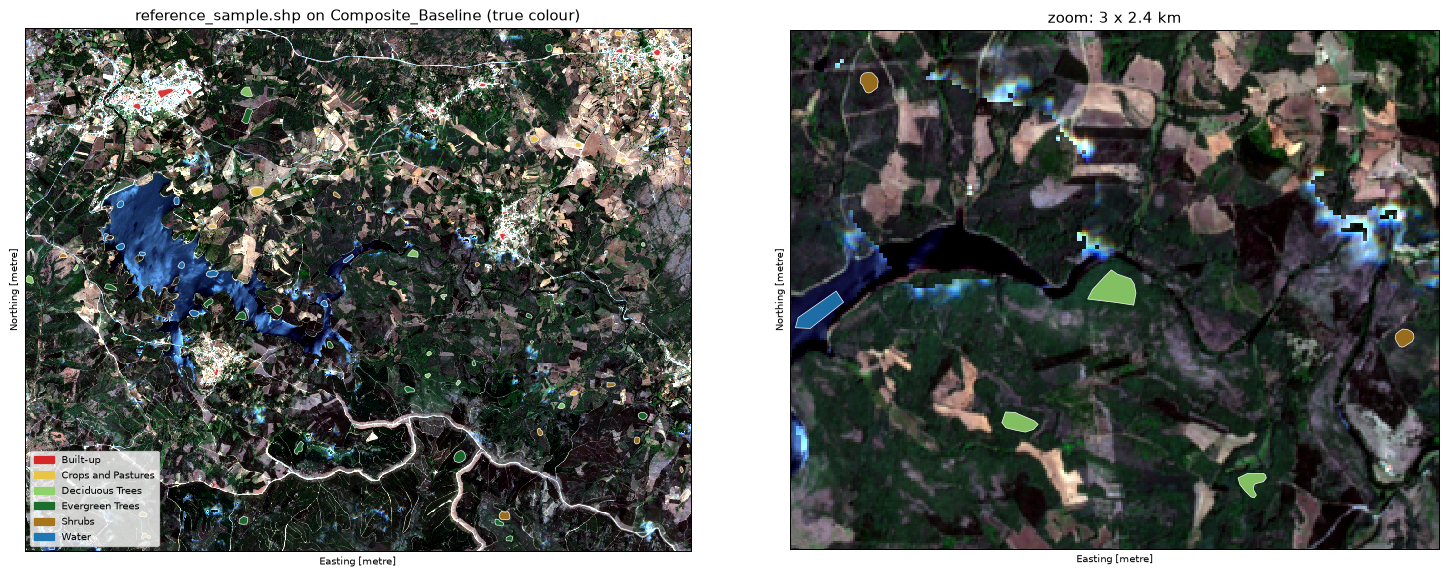

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
for ax in axes:
    ax.imshow(true_colour(base, base_valid), extent=EXTENT)
    for k, (name, colour) in CLASSES.items():
        ref[ref["classvalue"] == k].plot(ax=ax, facecolor=colour, edgecolor="white", lw=0.6, alpha=0.9)
axes[0].set_title("reference_sample.shp on Composite_Baseline (true colour)")
axes[0].legend(handles=CLASS_LEGEND, loc="lower left", fontsize=8)
x, y = ref.geometry.iloc[0].centroid.coords[0]
axes[1].set_xlim(x - 1500, x + 1500); axes[1].set_ylim(y - 1200, y + 1200)
axes[1].set_title("zoom: 3 x 2.4 km")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

## Data Splitting (Train/Test)
### Random Sampling
> ArcGIS offers an out-of-the-box tool that allows to split a feature dataset into training and test sets.
>
> 1. Load the reference_sample.shp into ArcGIS
> 2. Search for the Subset Features tool in the Geoprocessing toolbox
> 3. Select the reference_sample as the Input Features
> 4. Name the Output Training Feature Class as train_set and Output Test Feature Class as test_set
> 5. Define the Size of Training Feture Subset as 80 and in the Subset Size Units select PERCENTAGE_OF_INPUT
>
> The data will be split into 80% for training and 20% for test.
>
> Analyze the resulting train and test samples. Are they a good representation of the population?

**In Python:** Subset Features picks a random 80 % of the *features*, i.e. polygons, so the split is already by
polygon. `GeoDataFrame.sample(frac=0.8)` does the same, and the rest is the test set. The table counts what each
class gets, in polygons and in pixels, since the classifier is trained on pixels.

In [5]:
def split_table(train, test):
    # Polygons and pixels per class on each side of a split.
    t = {}
    for side, polys in (("train", train), ("test", test)):
        g = polys.assign(pixels=PX_PER_POLY[polys.index]).groupby("classvalue")
        t[("polygons", side)], t[("pixels", side)] = g.size(), g["pixels"].sum()
    t = pd.DataFrame(t).reindex(CLASS_IDS).fillna(0).astype(int)
    t[("test share %", "polygons")] = (100 * t["polygons"]["test"] / t["polygons"].sum(axis=1)).round(1)
    t[("test share %", "pixels")] = (100 * t["pixels"]["test"] / t["pixels"].sum(axis=1)).round(1)
    t.index = pd.Index(CLASS_NAMES, name="class")
    return t


train_set = ref.sample(frac=TRAIN_FRAC, random_state=SEED)
test_set = ref.drop(train_set.index)
print(f"train_set: {len(train_set)} polygons   test_set: {len(test_set)} polygons")
split_table(train_set, test_set)

train_set: 76 polygons   test_set: 19 polygons


polygons pixels polygons pixels test share %       
                      train  train     test   test     polygons pixels
class                                                                 
Built-up                 13   1410        4    223         23.5   13.7
Crops and Pastures       13   1520        2    104         13.3    6.4
Deciduous Trees          13   1336        2    181         13.3   11.9
Evergreen Trees          15   3021        4    615         21.1   16.9
Shrubs                   11   1143        4    316         26.7   21.7
Water                    11   1467        3    312         21.4   17.5

**Are they a good representation?** Not reliably. With only 14–19 polygons per class, a purely random draw of 19 test
polygons leaves the class shares to chance. With `SEED = 42`, Crops and Deciduous get only 2 test polygons each
(13 %) while Shrubs gets 4 (27 %). Their accuracies would then rest on two polygons. In pixels it's more uneven still,
because polygon sizes vary from 15 to 453 px: Crops gets 6 % of its pixels in the test set, Shrubs 22 %. Change `SEED`
to see how much it moves.

### Stratified Sampling
> Unfortunately, ArcGIS does not offer a straightforward tool to perform stratified sampling. A possible workaround is
> presented in the steps below:
>
> 1. Split the reference sample by class
>    - Search for the Split by Attributes tool in the Geoprocessing toolbox
>    - Set the Input Table or Features to the reference_sample
>    - In the Target Workspace create a folder called split_class in the Lab_3 folder. Select the split_class folder
>    - For Split Fields select classname
>    - This will create 6 feature classes, one for each class in the reference sample, in the split_class folder
> 2. Subset each class into train and test sets
>    - Search for the Subset Features tool in the Geoprocessing toolbox. Right-click on it and select Batch. Accept the
>      default parameters and click Next
>    - Add all the individual class shapefiles as inputs
>    - Set the Size of Training Feture Subset to 80 and in the Subset Size Units select PERCENTAGE_OF_INPUT
>    - Run the tool
> 3. Merge training subsets
>    - Search for the Merge tool in the Geoprocessing toolbox
>    - Add the training subsets of each class as the Input Datasets
>    - Name the Output Dataset as train_set_stratified
> 4. Merge test subsets
>    - Search for the Merge tool in the Geoprocessing toolbox
>    - Add the test subsets of each class as the Input Datasets
>    - Name the Output Dataset as test_set_stratified

**In Python:** all four steps are one line. `groupby("classvalue").sample(frac=0.8)` draws 80 % of the polygons
*within each class* (Split by Attributes + batch Subset Features), and the result stays one table (the Merges). There
is no `split_class` folder and there are no per-class shapefiles. Both sets are saved to one GeoPackage so you can
look at them in QGIS/ArcGIS.

(`sklearn.model_selection.train_test_split(ref, train_size=0.8, stratify=ref["classvalue"])` does the same, but it
rounds over the whole dataset instead of per class.)

In [6]:
train_set_stratified = ref.groupby("classvalue", group_keys=False).sample(frac=TRAIN_FRAC, random_state=SEED)
test_set_stratified = ref.drop(train_set_stratified.index)
print(f"train_set_stratified: {len(train_set_stratified)} polygons   "
      f"test_set_stratified: {len(test_set_stratified)} polygons")

samples_gpkg = OUT_DIR / "lab3_samples.gpkg"
for layer, gdf in {"train_set": train_set, "test_set": test_set,
                   "train_set_stratified": train_set_stratified,
                   "test_set_stratified": test_set_stratified}.items():
    gdf.to_file(samples_gpkg, layer=layer)
print("wrote", samples_gpkg)
split_table(train_set_stratified, test_set_stratified)

train_set_stratified: 76 polygons   test_set_stratified: 19 polygons
wrote outputs/Lab_3/lab3_samples.gpkg


polygons pixels polygons pixels test share %       
                      train  train     test   test     polygons pixels
class                                                                 
Built-up                 14   1402        3    231         17.6   14.1
Crops and Pastures       12   1333        3    291         20.0   17.9
Deciduous Trees          12    926        3    591         20.0   39.0
Evergreen Trees          15   2594        4   1042         21.1   28.7
Shrubs                   12   1092        3    367         20.0   25.2
Water                    11   1373        3    406         21.4   22.8

Every class now has 3–4 test polygons (≈ 20 %). In **pixels** the test share still ranges from 14 % (Built-up) to
39 % (Deciduous, whose three test polygons happen to be large), because polygon size is not controlled. Balancing
pixel counts as well, or splitting by cells of a spatial grid, would fix that. The rest of the notebook keeps the
lab's per-class polygon split.

## Classification
> This section is dedicated to performing a land cover classification based on the Random Forest classifier (referred
> to as Random Trees in ArcGIS).
>
> Two main approaches are described in this section:
>
> - Express Classification: A fast and straightforward method for generating a preliminary land-cover map quickly
>   without the extra steps of model tuning or statistical validation
> - End-to-end Workflow: A comprehensive pipeline that trains the Random Forest classifier and validates the final map
>   using the test dataset and a confusion matrix.

**In Python:** the two approaches use the same code. ArcGIS's *Classify (Random Trees)* and *Forest-based
Classification* are both random forests with different defaults, so `RandomForestClassifier` is set up to match each.
Classifying the whole 1 400 × 1 100 image takes a few seconds, so mapping first or evaluating first makes no
practical difference here.

### Express Classification and Accuracy Assessment
> Follow the steps below to conduct an express classification on ArcGIS:
>
> 1. In the Contents pane, select the input image (e.g. Composite_Baseline )
> 2. Go to Imagery > Classification Tools > Classify
> 3. Configure the classification parameters:
>    - Classifier: Random Trees (ArcGIS version of Random Forest)
>    - Training Samples: train_set_stratified
>    - Maximum Number of Samples per Class: 0 (set to zero to use all available samples)
>    - Output Classified Dataset: name the output as clf_base_express
> 4. Run the image classification. The classification map will be displayed when the classification is completed
> 5. For the accuracy assessment, search for the Compute Accuracy For Pixel Classification tool
>    - Input Raster: clf_base_express
>    - Ground Truth Data: test_set_stratified
>    - Number of Random Points: 1,000
>    - Run the tool
> 6. Inspect the confusion matrix under Standalone Tables

**In Python:**
- **Classify** = take the pixels under the training polygons, fit a forest, predict every pixel. `pixels_in` does the
  first part. ArcGIS's Random Trees defaults are 50 trees and max depth 30. "0 samples per class = use all" is what
  sklearn does anyway.
- **Compute Accuracy For Pixel Classification** reads the map at 1 000 random points inside the test polygons. All
  test pixels are already known, so here the map is read at *all* of them: no sampling noise, nothing to set.

In [7]:
train_set_points = pixels_in(train_set_stratified, base, base_valid, TRANSFORM, BASE_BANDS)
test_set_points = pixels_in(test_set_stratified, base, base_valid, TRANSFORM, BASE_BANDS)
print(f"training pixels: {len(train_set_points):,}   test pixels: {len(test_set_points):,}")

random_trees = RandomForestClassifier(n_estimators=50, max_depth=30, n_jobs=-1, random_state=SEED)
random_trees.fit(train_set_points[BASE_BANDS], train_set_points["classvalue"])
clf_base_express = classify(random_trees, base, base_valid, BASE_BANDS)
write_class_map(OUT_DIR / "clf_base_express.tif", clf_base_express, TRANSFORM, CRS)

# accuracy: the map's class at every test pixel vs the polygon's class
express_pred = clf_base_express[test_set_points["row"], test_set_points["col"]]
print({k: round(v, 3) for k, v in scores(test_set_points["classvalue"], express_pred).items()})
arcgis_confusion_matrix(express_pred, test_set_points["classvalue"])

training pixels: 8,720   test pixels: 2,928


wrote outputs/Lab_3/clf_base_express.tif
{'overall accuracy': 0.66, 'kappa': 0.569, 'macro F1': 0.671}


,Built-up,Crops and Pastures,Deciduous Trees,Evergreen Trees,Shrubs,Water,Total,U_Accuracy,Kappa
Classified \ GrndTruth,,,,,,,,,
Built-up,223,64,0,0,45,0,332,0.672,
Crops and Pastures,8,227,12,123,59,0,429,0.529,
Deciduous Trees,0,0,156,0,0,0,156,1.000,
Evergreen Trees,0,0,412,687,29,0,1128,0.609,
Shrubs,0,0,11,230,234,0,475,0.493,
Water,0,0,0,2,0,406,408,0.995,
Total,231,291,591,1042,367,406,2928,,
P_Accuracy,0.965,0.780,0.264,0.659,0.638,1.000,,0.660,
Kappa,,,,,,,,,0.569


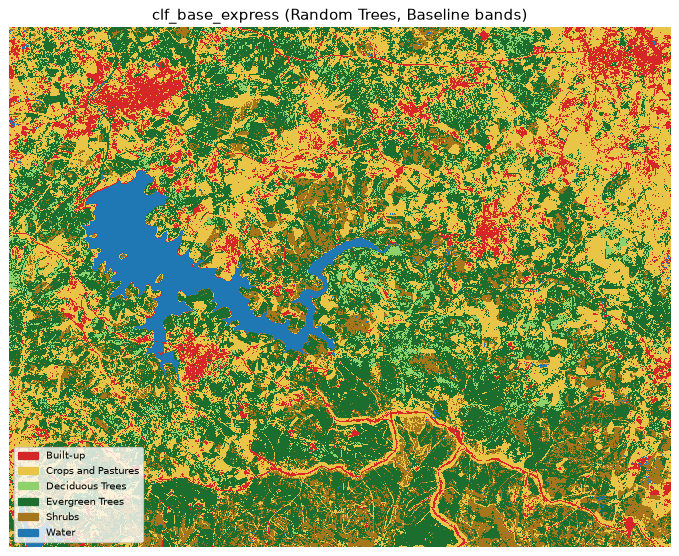

In [8]:
fig, ax = plt.subplots(figsize=(10, 7.5))
show_class_map(ax, clf_base_express, "clf_base_express (Random Trees, Baseline bands)")
ax.legend(handles=CLASS_LEGEND, loc="lower left", fontsize=8);

### End-to-end Workflow
The handout's reason for this workflow: evaluate the trained model on the test set *before* making the map, since
mapping is the expensive step in ArcGIS.

#### Preparing the training and test data
> 1. Open Lab_3_Toolbox
> 2. Run the Extract_Points_Lab3 tool
>    - Select the Composite_Baseline.tif as the Input raster
>    - Select the train_set_stratified as the Polygon Layer
>    - Name the Output point features as train_set_points
> 3. Repeat the same process, but this time for the test set
> 4. Select the Composite_Baseline.tif as the Input raster
>    - Select the test_set_stratified as the Polygon Layer
>    - Name the Output point features as test_set_points

**In Python:** inside the toolbox, Extract_Points_Lab3 runs *Extract by Mask* (keep pixels whose centre is inside a
polygon) → *Raster to Point* (one point per pixel) → *Join Attributes from Polygon* (copy `classname`/`classvalue`
onto the points). `pixels_in` does all three with one `rasterize`, and also attaches the band values, which in
ArcGIS the next tool reads from the raster. `train_set_points` and `test_set_points` already exist from the express
step. Here is what they hold, also saved as point layers:

In [9]:
points_gpkg = OUT_DIR / "lab3_points.gpkg"
train_set_points.to_file(points_gpkg, layer="train_set_points")
test_set_points.to_file(points_gpkg, layer="test_set_points")
print("wrote", points_gpkg)
display(train_set_points.head())
pd.DataFrame({"train_set_points": train_set_points["classvalue"].value_counts(),
              "test_set_points": test_set_points["classvalue"].value_counts()}
             ).reindex(CLASS_IDS).set_axis(CLASS_NAMES)

wrote outputs/Lab_3/lab3_points.gpkg


,polygon,classvalue,Blue,Green,Red,NIR,row,col,geometry
0,70,2,1528.0,1814.0,2283.0,3419.0,6,1243,POINT (672435 4469935)
1,70,2,1540.0,1834.0,2326.0,3342.0,6,1244,POINT (672445 4469935)
2,70,2,1538.0,1845.0,2350.0,3335.0,6,1245,POINT (672455 4469935)
3,70,2,1534.0,1823.0,2334.0,3297.0,6,1246,POINT (672465 4469935)
4,70,2,1545.0,1849.0,2341.0,3325.0,6,1247,POINT (672475 4469935)


,train_set_points,test_set_points
Built-up,1402,231
Crops and Pastures,1333,291
Deciduous Trees,926,591
Evergreen Trees,2594,1042
Shrubs,1092,367
Water,1373,406


#### Train Random Forest Model
> 1. Open the Forest-based and Boosted Classification and Regression tool
> 2. Configure the tool as follows:
>    - Prediction Type: Predict to features
>    - Model Type: Forest-based
>    - Input Training Features: train_set_points
>    - Variable to Predict: classvalue (check the Treat Variable as Categorical box)
>    - Explanatory Training Rasters: Click on the folder icon and navigate to the Composite_Baseline.tif . Double click
>      on the tif file to see the 4 bands. Select all bands and press OK
>    - Input Prediction Features: test_set_points
>    - Output Predicted Features: out_test
>    - Output Trained Model File: model_rf_baseline
>    - Output Trained Features: out_train
>    - Run the tool to start model training
> 3. Inspect the out_train and out_test datasets on the map
>
> You can change some hyperparameters (e.g. Number of Trees) to try to improve the model's performance

**In Python:**
- Forest-based defaults are 100 trees and √(number of variables) per split, i.e. `RandomForestClassifier(n_estimators=100,
  max_features="sqrt")`. "Treat Variable as Categorical" = use a classifier, not a regressor.
- The tool also holds out 10 % of the training points as validation. A random forest doesn't need that: each tree
  never sees ~37 % of the pixels (its out-of-bag sample), and `oob_score=True` scores on those for free.
  **Caveat:** OOB is per pixel, so a pixel's neighbours from the same polygon are usually in-bag, which makes the
  OOB score optimistic. The held-out polygons are the honest number.
- The `.ssm` model file becomes a `joblib` file.

In [10]:
model_rf_baseline = RandomForestClassifier(n_estimators=100, max_features="sqrt", oob_score=True,
                                           n_jobs=-1, random_state=SEED)
model_rf_baseline.fit(train_set_points[BASE_BANDS], train_set_points["classvalue"])
joblib.dump(model_rf_baseline, OUT_DIR / "model_rf_baseline.joblib")

out_train = train_set_points.assign(PREDICTED=model_rf_baseline.predict(train_set_points[BASE_BANDS]))
out_test = test_set_points.assign(PREDICTED=model_rf_baseline.predict(test_set_points[BASE_BANDS]))
pd.Series({
    "out_train (pixels the model was fit on)": accuracy_score(out_train["classvalue"], out_train["PREDICTED"]),
    "out-of-bag (training pixels, per tree)": model_rf_baseline.oob_score_,
    "out_test (held-out polygons)": accuracy_score(out_test["classvalue"], out_test["PREDICTED"]),
}, name="overall accuracy").round(3).to_frame()

,overall accuracy
out_train (pixels the model was fit on),1.000
"out-of-bag (training pixels, per tree)",0.951
out_test (held-out polygons),0.662


The gap is the point of the train/test split: a forest of deep trees nearly memorises its training pixels, OOB is a
bit lower but still optimistic, and only the test polygons show how the model does on places it hasn't seen.
Below, step 3, "inspect out_train and out_test on the map": correctly classified pixels in green, wrong ones in red.

Share of misclassified pixels in each test polygon:


,% wrong per polygon
Built-up,"[6, 2, 0]"
Crops and Pastures,"[2, 0, 51]"
Deciduous Trees,"[96, 17, 100]"
Evergreen Trees,"[45, 8, 60, 17]"
Shrubs,"[8, 13, 99]"
Water,"[0, 0, 0]"


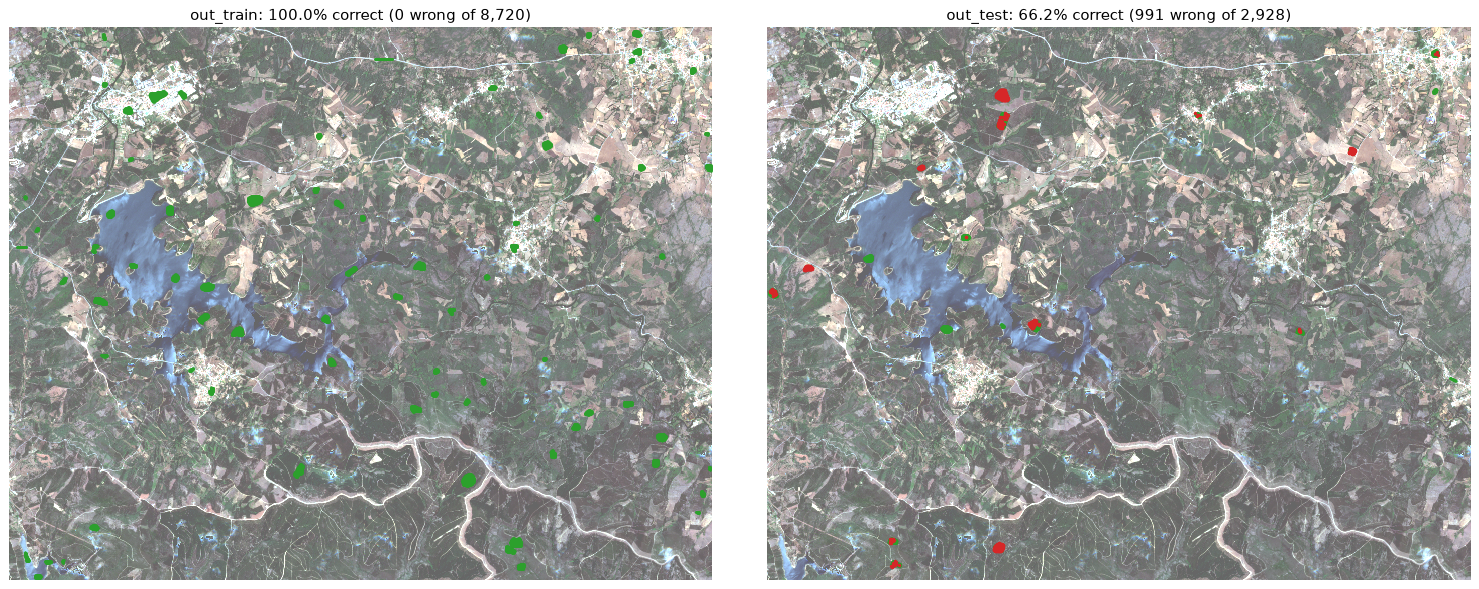

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, pts, title in zip(axes, (out_train, out_test), ("out_train", "out_test")):
    ax.imshow(true_colour(base, base_valid), extent=EXTENT, alpha=0.6)
    ok = pts["PREDICTED"] == pts["classvalue"]
    for sel, colour, size in ((ok, "#2ca02c", 1), (~ok, "#d62728", 3)):
        if sel.any():
            pts[sel].plot(ax=ax, color=colour, markersize=size)
    ax.set_title(f"{title}: {ok.mean():.1%} correct ({(~ok).sum():,} wrong of {len(pts):,})"); ax.set_axis_off()
plt.tight_layout()

wrong = (out_test.assign(wrong=out_test["PREDICTED"] != out_test["classvalue"])
         .groupby(["classvalue", "polygon"])["wrong"].mean().unstack(0).set_axis(CLASS_NAMES, axis=1))
print("Share of misclassified pixels in each test polygon:")
display((100 * wrong).round(0).apply(lambda c: c.dropna().astype(int).tolist()).to_frame("% wrong per polygon"))

**Variable importance.** The Forest-based tool reports variable importance. sklearn's `feature_importances_` is the
same impurity-based measure, which tends to favour correlated bands somewhat arbitrarily. *Permutation
importance* on the test set (how much accuracy drops when one band is shuffled) is the more reliable of the two.

,impurity (train),"permutation (test), accuracy drop"
Blue,0.258,0.187
Green,0.133,0.051
Red,0.251,0.217
NIR,0.358,0.264


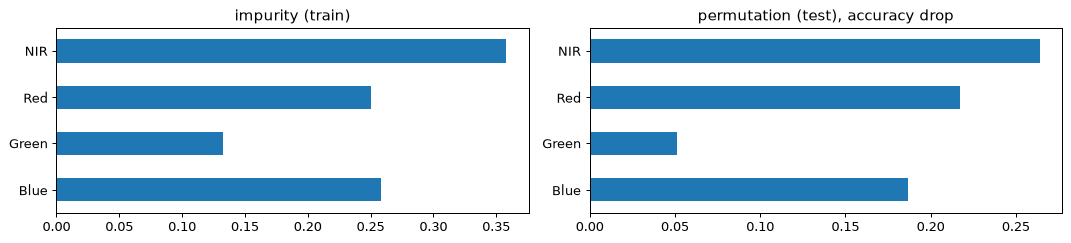

In [12]:
perm = permutation_importance(model_rf_baseline, test_set_points[BASE_BANDS], test_set_points["classvalue"],
                              n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"impurity (train)": model_rf_baseline.feature_importances_,
                    "permutation (test), accuracy drop": perm.importances_mean}, index=BASE_BANDS)
imp.plot.barh(subplots=True, layout=(1, 2), figsize=(12, 2.8), legend=False, sharex=False, color="tab:blue")
plt.tight_layout()
imp.round(3)

**Hyperparameters ("You can change some hyperparameters").** Tuning against the test set would make the test score
optimistic. The usual approach is cross-validation *within the training set*, with folds grouped by polygon so the
validation pixels come from unseen polygons (`StratifiedGroupKFold`). A few settings:

In [13]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = [dict(n_estimators=n, min_samples_leaf=leaf, max_features=mf)
        for n in (50, 100, 300) for leaf in (1, 5, 20) for mf in ("sqrt", None)]
rows = []
for params in grid:
    res = cross_validate(RandomForestClassifier(n_jobs=-1, random_state=SEED, **params),
                         train_set_points[BASE_BANDS], train_set_points["classvalue"],
                         groups=train_set_points["polygon"], cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({**params, "CV accuracy": res["test_accuracy"].mean(), "± sd": res["test_accuracy"].std(),
                 "CV macro F1": res["test_f1_macro"].mean()})
tuning = pd.DataFrame(rows).sort_values("CV accuracy", ascending=False)
tuning["max_features"] = tuning["max_features"].fillna("all")
tuning.round(3).reset_index(drop=True)

,n_estimators,min_samples_leaf,max_features,CV accuracy,± sd,CV macro F1
0,100,5,sqrt,0.872,0.040,0.870
1,300,1,sqrt,0.872,0.043,0.871
2,100,1,sqrt,0.872,0.042,0.870
3,50,5,sqrt,0.871,0.040,0.869
4,300,5,sqrt,0.870,0.038,0.869
5,50,1,sqrt,0.869,0.042,0.868
6,300,1,all,0.859,0.046,0.860
7,100,1,all,0.858,0.045,0.859
8,50,1,all,0.858,0.045,0.859
9,100,20,sqrt,0.858,0.032,0.855


All 18 settings land within 0.84–0.87, about one fold standard deviation (≈ 0.04) apart. What shows:
- the **number of trees** (the hyperparameter the lab suggests) makes no difference from 50 trees up;
- a **random subset of bands per split** (`sqrt`, i.e. 2 of 4) beats letting every split see all bands. That
  randomness is what decorrelates the trees;
- leaves of 1 or 5 pixels are the same, and 20 is slightly worse.

With 4 bands and ~8 700 pixels from 76 polygons, the model is limited by what the bands can separate, not by the
hyperparameters. The Forest-based defaults are kept, and they are also the best setting here.

#### Evaluate Model Accuracy
> 1. Open the Prepare_Predicted_Points_Lab3 tool in the Lab_3_Toolbox
>    - In Test Polygons, select test_set_stratified
>    - In Predictions (Points), select out_test
> 2. Now the out_test points have two columns that allow ArcGIS to compute a confusion matrix (Classified and
>    GrndTruth)
> 3. Open the Compute Confusion Matrix tool
>    - Input Accuracy Assessment Points: out_test
>    - Output Confusion Matrix: CM_Baseline
>    - Run the tool to compute the confusion matrix
> 4. The confusion matrix will be added to the contents pane (under Standalone Tables at the bottom). Inspect the
>    confusion matrix (open attribute table)

**In Python:** inside the toolbox, Prepare_Predicted_Points_Lab3 spatially joins the test polygons back onto
`out_test` to recover the true class, then renames `PREDICTED` → `Classified` and `classvalue` → `GrndTruth`.
The test pixels here never lost their class, so only the rename is left, kept for parity. *Compute Confusion Matrix*
is `sklearn.metrics.confusion_matrix`. The table uses ArcGIS's layout: rows = classified, columns = ground truth,
`U_Accuracy` = user's accuracy (precision), `P_Accuracy` = producer's accuracy (recall), overall accuracy where the
two meet, kappa in the corner. `classification_report` adds per-class F1.

In [14]:
out_test = out_test.rename(columns={"PREDICTED": "Classified", "classvalue": "GrndTruth"})
CM_Baseline = arcgis_confusion_matrix(out_test["Classified"], out_test["GrndTruth"])
display(CM_Baseline)
print(classification_report(out_test["GrndTruth"], out_test["Classified"], labels=CLASS_IDS,
                            target_names=CLASS_NAMES, digits=3))

,Built-up,Crops and Pastures,Deciduous Trees,Evergreen Trees,Shrubs,Water,Total,U_Accuracy,Kappa
Classified \ GrndTruth,,,,,,,,,
Built-up,224,64,0,0,47,0,335,0.669,
Crops and Pastures,7,227,13,124,58,0,429,0.529,
Deciduous Trees,0,0,158,0,0,0,158,1.000,
Evergreen Trees,0,0,408,685,25,0,1118,0.613,
Shrubs,0,0,12,231,237,0,480,0.494,
Water,0,0,0,2,0,406,408,0.995,
Total,231,291,591,1042,367,406,2928,,
P_Accuracy,0.970,0.780,0.267,0.657,0.646,1.000,,0.662,
Kappa,,,,,,,,,0.571


                    precision    recall  f1-score   support

          Built-up      0.669     0.970     0.792       231
Crops and Pastures      0.529     0.780     0.631       291
   Deciduous Trees      1.000     0.267     0.422       591
   Evergreen Trees      0.613     0.657     0.634      1042
            Shrubs      0.494     0.646     0.560       367
             Water      0.995     1.000     0.998       406

          accuracy                          0.662      2928
         macro avg      0.717     0.720     0.673      2928
      weighted avg      0.725     0.662     0.644      2928



**Reading it.** Water and Built-up are nearly perfect. The weak spot is **Deciduous Trees**: about 70 % of its test
pixels are classified as Evergreen (producer's accuracy ≈ 0.27), and two of its three test polygons are almost
entirely wrong (the "% wrong per polygon" table above). In a late-June composite, deciduous trees are in full leaf,
so with only Blue/Green/Red/NIR they look like evergreen. Evergreen in turn is mixed up with Shrubs and Crops.

Why is the test accuracy (≈ 0.66) so much lower than the cross-validated ≈ 0.87 in the tuning step? The test set is
3–4 polygons per class, and accuracy is counted in pixels, so the three large deciduous polygons (591 px, 20 % of the
test set) weigh heavily. The exercise below compares models over all polygons for that reason.

#### Create Classification Map
> If the model accuracy evaluated on the test set is satisfactory, we can proceed to using the model to create a
> classification map for our whole study area.
>
> 1. Open the Predict Using Spatial Statistic Model file tool
> 2. Use the settings below:
>    - Input Model File: model_rf_baseline.ssm
>    - Prediction Type: Predict to raster
>    - Output Predicted Raster: map_clf_baseline
>    - Click on the folder icon and navigate to the Composite_Baseline.tif . Double click on the tif file to see the 4
>      bands. Select all bands and press OK. Make sure the Prediction bands match the Training bands
>    - Run the prediction to create the map
> 3. Inspect the classification map

**In Python:** `model.predict` on every valid pixel, as a (pixels × bands) table. "Make sure the Prediction bands
match the Training bands" is checked automatically: the model was fit on named columns, and sklearn raises an error
if the prediction columns differ. The map is written as a uint8 GeoTIFF with an embedded colour table.

wrote outputs/Lab_3/map_clf_baseline.tif


,km²,% of map
Built-up,12.01,7.8
Crops and Pastures,50.35,32.7
Deciduous Trees,6.10,4.0
Evergreen Trees,61.11,39.7
Shrubs,17.49,11.4
Water,6.94,4.5


map_clf_baseline and clf_base_express agree on 98.3% of pixels


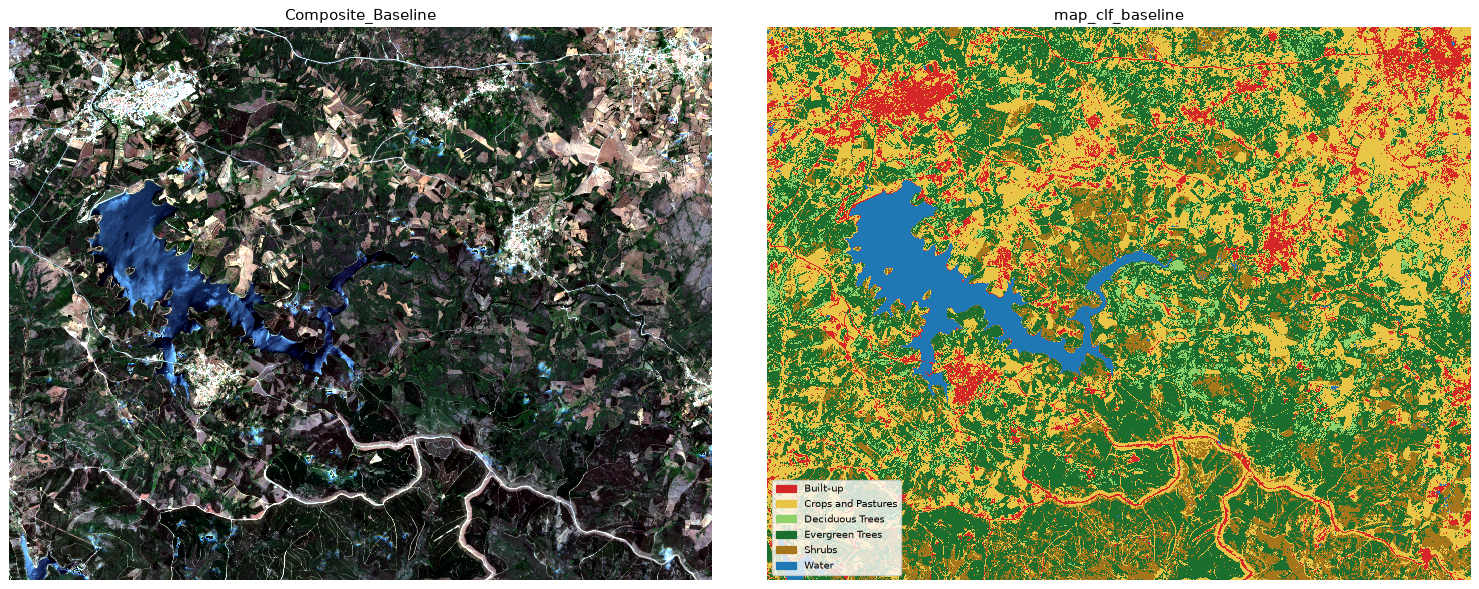

In [15]:
model = joblib.load(OUT_DIR / "model_rf_baseline.joblib")      # Input Model File
map_clf_baseline = classify(model, base, base_valid, BASE_BANDS)
write_class_map(OUT_DIR / "map_clf_baseline.tif", map_clf_baseline, TRANSFORM, CRS)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
axes[0].imshow(true_colour(base, base_valid), extent=EXTENT); axes[0].set_title("Composite_Baseline"); axes[0].set_axis_off()
show_class_map(axes[1], map_clf_baseline, "map_clf_baseline")
axes[1].legend(handles=CLASS_LEGEND, loc="lower left", fontsize=8)
plt.tight_layout()

px_km2 = abs(TRANSFORM.a * TRANSFORM.e) / 1e6
counts = pd.Series(map_clf_baseline[base_valid]).value_counts().reindex(CLASS_IDS, fill_value=0)
display(pd.DataFrame({"km²": (counts * px_km2).round(2), "% of map": (100 * counts / counts.sum()).round(1)},
                     index=CLASS_IDS).set_axis(CLASS_NAMES))
agree = (map_clf_baseline == clf_base_express)[base_valid].mean()
print(f"map_clf_baseline and clf_base_express agree on {agree:.1%} of pixels")

## Exercise
> Load the Composite_NDVI created during the last Lab. In addition to the 4 bands of the baseline composite, it has
> the NDVI as the fifth band.
>
> Train a Random Trees model using the Composite_NDVI as the input. Evaluate the accuracy on the test set. Compare the
> accuracy of this model to the baseline model to assess if including the NDVI improved the predictive capabilities of
> the model.
>
> Similarly, repeat the process using the bi-temporal composite created in the last Lab.

**In Python:** the end-to-end workflow becomes a function and runs on each composite with the *same* stratified
split, so the models differ only in their input bands. The bi-temporal composite (`Composite_temporal.tif`, written
by the Lab 2 exercise) is used if it is found in the composites folder, `data/Lab_3` or `outputs/Lab_2`.

Note: the `Composite_NDVI.tif` shipped with Lab 3 has ArcGIS's NDVI computed on raw DNs (offset not removed).
With `LAB3_COMPOSITES=outputs/Lab_2` you get the reflectance-based NDVI from the Python Lab 2.

In [16]:
def end_to_end(path, train_polys=train_set_stratified, test_polys=test_set_stratified):
    # Extract_Points -> Forest-based classification -> confusion-matrix inputs, for one composite.
    arr, valid, transform, crs, names = read_composite(path)
    assert transform == TRANSFORM and crs == CRS, f"{path.name} is not on the Baseline grid"
    train = pixels_in(train_polys, arr, valid, transform, names)
    test = pixels_in(test_polys, arr, valid, transform, names)
    model = RandomForestClassifier(n_estimators=100, max_features="sqrt", oob_score=True,
                                   n_jobs=-1, random_state=SEED).fit(train[names], train["classvalue"])
    test = test.assign(PREDICTED=model.predict(test[names]))
    return dict(path=path, bands=names, model=model, test=test, arr=arr, valid=valid)


temporal_path = next((p for p in (COMPOSITE_DIR / "Composite_temporal.tif", DATA_DIR / "Composite_temporal.tif",
                                  Path("outputs/Lab_2/Composite_temporal.tif")) if p.exists()), None)
composites = {"Baseline": COMPOSITE_DIR / "Composite_Baseline.tif", "Baseline + NDVI": COMPOSITE_DIR / "Composite_NDVI.tif"}
if temporal_path:
    composites["Bi-temporal"] = temporal_path
else:
    print("No Composite_temporal.tif found: run the Lab 2 exercise (or copy it to the composites folder) "
          "and re-run this cell to add the bi-temporal model.")

runs = {name: end_to_end(path) for name, path in composites.items()}
assert (runs["Baseline"]["test"]["PREDICTED"].to_numpy() == out_test["Classified"].to_numpy()).all()

for name, r in runs.items():
    print(f"{name:16s} {r['path'].name:24s} bands: {', '.join(r['bands'])}")

No Composite_temporal.tif found: run the Lab 2 exercise (or copy it to the composites folder) and re-run this cell to add the bi-temporal model.


Baseline         Composite_Baseline.tif   bands: Blue, Green, Red, NIR
Baseline + NDVI  Composite_NDVI.tif       bands: Blue, Green, Red, NIR, NDVI


In [17]:
def per_class_f1(test):
    return pd.Series(f1_score(test["classvalue"], test["PREDICTED"], labels=CLASS_IDS, average=None),
                     index=[f"F1 {n}" for n in CLASS_NAMES])

comparison = pd.DataFrame({
    name: pd.concat([pd.Series(scores(r["test"]["classvalue"], r["test"]["PREDICTED"])),
                     pd.Series({"out-of-bag": r["model"].oob_score_}), per_class_f1(r["test"])])
    for name, r in runs.items()})
comparison.round(3)

,Baseline,Baseline + NDVI
overall accuracy,0.662,0.663
kappa,0.571,0.574
macro F1,0.673,0.675
out-of-bag,0.951,0.950
F1 Built-up,0.792,0.776
F1 Crops and Pastures,0.631,0.640
F1 Deciduous Trees,0.422,0.447
F1 Evergreen Trees,0.634,0.632
F1 Shrubs,0.560,0.559
F1 Water,0.998,0.999


In [18]:
for name, r in list(runs.items())[1:]:
    print(name)
    display(arcgis_confusion_matrix(r["test"]["PREDICTED"], r["test"]["classvalue"]))

Baseline + NDVI


,Built-up,Crops and Pastures,Deciduous Trees,Evergreen Trees,Shrubs,Water,Total,U_Accuracy,Kappa
Classified \ GrndTruth,,,,,,,,,
Built-up,224,63,0,1,58,0,346,0.647,
Crops and Pastures,7,228,15,125,47,0,422,0.540,
Deciduous Trees,0,0,170,0,0,0,170,1.000,
Evergreen Trees,0,0,397,675,23,0,1095,0.616,
Shrubs,0,0,9,240,239,0,488,0.490,
Water,0,0,0,1,0,406,407,0.998,
Total,231,291,591,1042,367,406,2928,,
P_Accuracy,0.970,0.784,0.288,0.648,0.651,1.000,,0.663,
Kappa,,,,,,,,,0.574


**Is the difference real?** The test set is 19 polygons, so one polygon going right or wrong moves the accuracy by
several points. A fairer comparison uses all 95 polygons: 5-fold cross-validation grouped by polygon and stratified by
class, repeated with 5 different shuffles. Every composite gets **the same folds**, so the per-fold differences
against the Baseline are paired.

In [19]:
REPEATS = 5
cv_scores = {}
for name, path in composites.items():
    arr, valid, transform, _, names = read_composite(path)
    px = pixels_in(ref, arr, valid, transform, names)
    acc = []
    for rep in range(REPEATS):
        res = cross_validate(RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED),
                             px[names], px["classvalue"], groups=px["polygon"], scoring="accuracy",
                             cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + rep))
        acc.extend(res["test_score"])
    cv_scores[name] = np.array(acc)

cv_table = pd.DataFrame({"CV accuracy (mean)": {k: v.mean() for k, v in cv_scores.items()},
                         "sd across folds": {k: v.std() for k, v in cv_scores.items()}})
for name, acc in cv_scores.items():
    d = acc - cv_scores["Baseline"]
    cv_table.loc[name, "mean diff vs Baseline"] = d.mean()
    cv_table.loc[name, "folds better / worse"] = f"{(d > 0).sum()} / {(d < 0).sum()}"
cv_table.round(3)

,CV accuracy (mean),sd across folds,mean diff vs Baseline,folds better / worse
Baseline,0.805,0.041,0.000,0 / 0
Baseline + NDVI,0.798,0.042,-0.007,10 / 15


wrote outputs/Lab_3/map_clf_baseline.tif


wrote outputs/Lab_3/map_clf_ndvi.tif


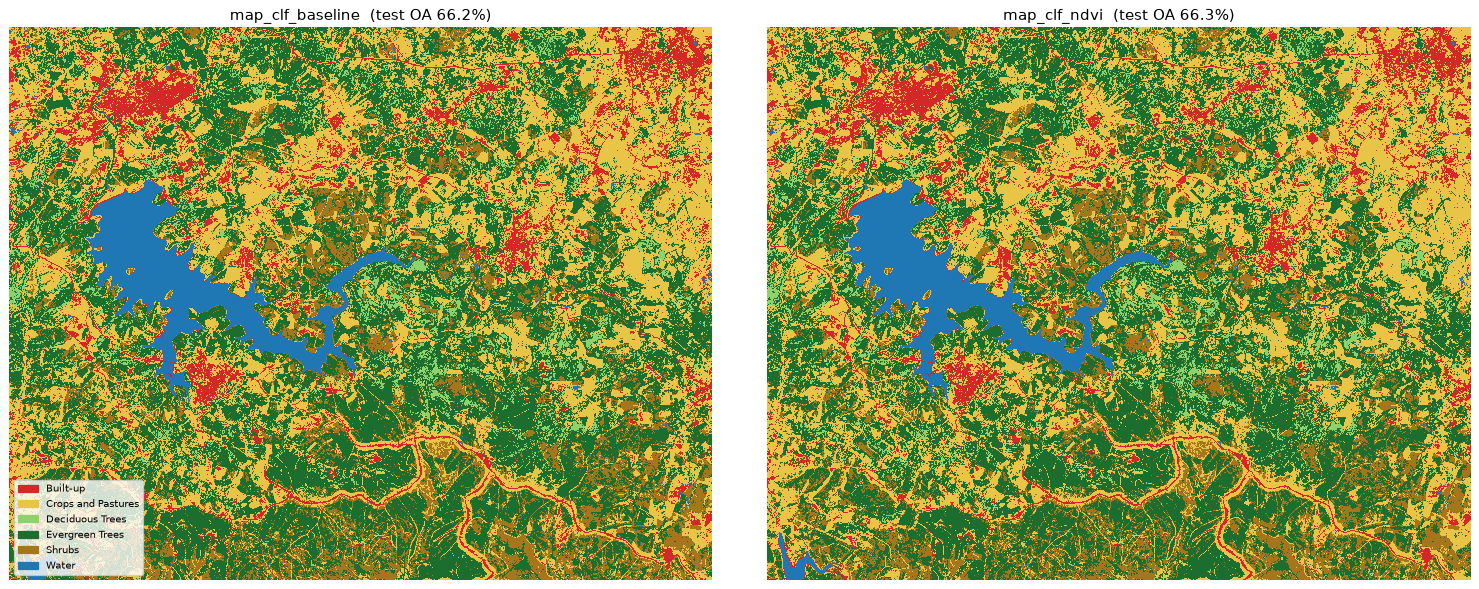

In [20]:
fig, axes = plt.subplots(1, len(runs), figsize=(8.5 * len(runs), 6.5), squeeze=False)
for ax, (name, r) in zip(axes[0], runs.items()):
    cls = classify(r["model"], r["arr"], r["valid"], r["bands"])
    tag = {"Baseline": "baseline", "Baseline + NDVI": "ndvi", "Bi-temporal": "temporal"}[name]
    write_class_map(OUT_DIR / f"map_clf_{tag}.tif", cls, TRANSFORM, CRS)
    oa = accuracy_score(r["test"]["classvalue"], r["test"]["PREDICTED"])
    show_class_map(ax, cls, f"map_clf_{tag}  (test OA {oa:.1%})")
axes[0][0].legend(handles=CLASS_LEGEND, loc="lower left", fontsize=8)
plt.tight_layout()

**Did NDVI help?** No. On the test set, + NDVI changes overall accuracy by about 0.1 points. Over 25 grouped CV folds
it is on average slightly *worse* (≈ −0.7 points, better in 10 folds, worse in 15), well inside the fold-to-fold
spread. That is expected: NDVI is computed from Red and NIR, which the forest already has, so it adds no new
information, only an easier split. It doesn't touch the main error either, Deciduous vs Evergreen, because both are
green in June.

That confusion is a **phenology** problem, and the bi-temporal composite targets exactly it: in winter deciduous
trees are leafless and evergreen ones are not. Once `Composite_temporal.tif` from the Lab 2 exercise is available,
re-run the exercise cells and check the Deciduous/Evergreen F1 in the comparison table.

## Outputs

In [21]:
pd.DataFrame([{"file": p.name, "MB": round(p.stat().st_size / 1e6, 2)}
              for p in sorted(OUT_DIR.iterdir()) if not p.name.startswith(".")]).set_index("file")

,MB
file,
clf_base_express.tif,0.29
lab3_points.gpkg,1.52
lab3_samples.gpkg,0.23
map_clf_baseline.tif,0.29
map_clf_ndvi.tif,0.29
model_rf_baseline.joblib,10.14
